# 03 — Exploratory Data Analysis

**Movie Ticket Booking Analytics · synthetic dataset v2**

All data is synthetic — patterns in a generated dataset, not claims about real cinema markets.

## 0. Setup

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CLEAN = ROOT / 'data' / 'clean' / 'bookings_clean.csv'
FIGDIR = ROOT / 'reports' / 'figures'
FIGDIR.mkdir(parents=True, exist_ok=True)

RED = '#B3122F'
CHARCOAL = '#1F2933'
GOLD = '#C9A227'
GREY = '#8C8C8C'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': CHARCOAL,
    'axes.labelcolor': CHARCOAL, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--',
})

def inr(value, pos=None):
    if value >= 1e7: return f'{value/1e7:.1f}Cr'
    if value >= 1e5: return f'{value/1e5:.0f}L'
    if value >= 1e3: return f'{value/1e3:.0f}k'
    return f'{value:.0f}'

def save(fig, name):
    path = FIGDIR / name
    fig.savefig(path, bbox_inches='tight')
    print(f'saved {name}')

## 1. Load and validate

In [2]:
df = pd.read_csv(CLEAN, dtype={'phone': 'string'})
df['show_date'] = pd.to_datetime(df['show_date'])
df['booking_datetime'] = pd.to_datetime(df['booking_datetime'])
df['lead_days'] = (df['show_date'] - df['booking_datetime'].dt.normalize()).dt.days
confirmed = df[df['booking_status'] == 'Confirmed'].copy()

revenue = int(confirmed['total_amount'].sum())
tickets = int(confirmed['seats'].sum())
print(f'Bookings: {len(df):,} | Confirmed: {len(confirmed):,} | Tickets: {tickets:,} | Revenue: ₹{revenue:,}')
assert len(df)==10000 and len(confirmed)==9311 and revenue==10787567
print('Anchors match SQL layer.')

Bookings: 10,000 | Confirmed: 9,311 | Tickets: 22,690 | Revenue: ₹10,787,567
Anchors match SQL layer.


## 2. When does the money arrive?

### 2.1 Monthly trend

saved 01_monthly_revenue.png


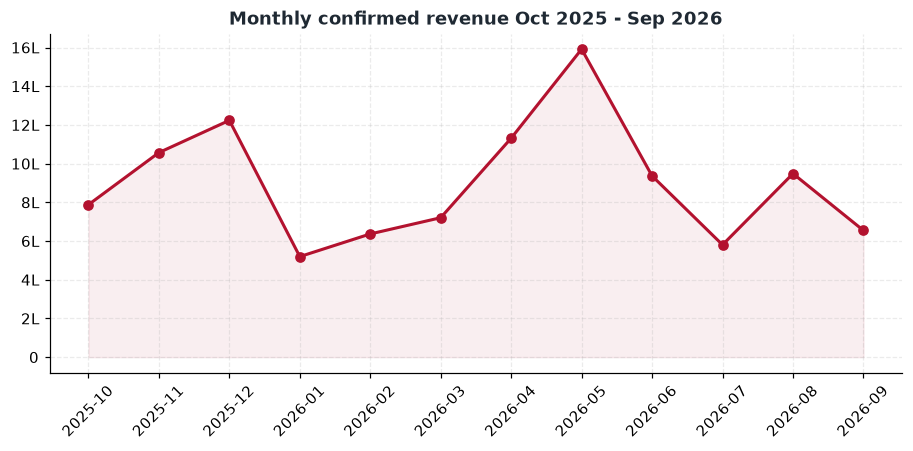

      month  revenue  bookings   mom
0   2025-10   787741       732   NaN
1   2025-11  1056911       834  34.2
2   2025-12  1223532      1040  15.8
3   2026-01   519563       523 -57.5
4   2026-02   636632       619  22.5
5   2026-03   720504       682  13.2
6   2026-04  1131470       919  57.0
7   2026-05  1591552      1202  40.7
8   2026-06   936395       850 -41.2
9   2026-07   580324       514 -38.0
10  2026-08   948386       805  63.4
11  2026-09   654557       591 -31.0


In [3]:
monthly = confirmed.assign(month=confirmed['show_date'].dt.to_period('M').astype(str)).groupby('month').agg(revenue=('total_amount','sum'),bookings=('booking_id','count')).reset_index()
fig,ax = plt.subplots(figsize=(10,4))
ax.plot(monthly['month'], monthly['revenue'], marker='o', color=RED, linewidth=2)
ax.fill_between(monthly['month'], monthly['revenue'], alpha=0.07, color=RED)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
plt.xticks(rotation=45)
ax.set_title('Monthly confirmed revenue Oct 2025 - Sep 2026')
save(fig,'01_monthly_revenue.png')
plt.show()
monthly['mom']=monthly['revenue'].pct_change()*100
print(monthly.round(1))

### 2.2 Day of week

saved 02_revenue_by_day.png


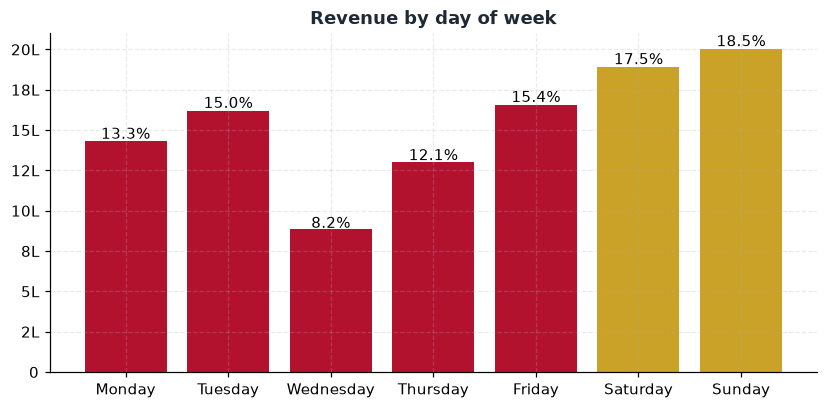

           revenue  bookings  share
day                                
Monday     1431892      1197   13.0
Tuesday    1621251      1452   15.0
Wednesday   885199       904    8.0
Thursday   1300983      1203   12.0
Friday     1657870      1487   15.0
Saturday   1889943      1479   18.0
Sunday     2000429      1589   19.0


In [4]:
DOW=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = confirmed.assign(day=confirmed['show_date'].dt.day_name()).groupby('day').agg(revenue=('total_amount','sum'),bookings=('booking_id','count'))
dow = dow.reindex(DOW)
dow['share']=dow['revenue']/dow['revenue'].sum()*100
colors=[GOLD if d in ['Saturday','Sunday'] else RED for d in dow.index]
fig,ax = plt.subplots(figsize=(9,4))
bars=ax.bar(dow.index, dow['revenue'], color=colors)
for b,s in zip(bars,dow['share']):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()*1.01,f'{s:.1f}%',ha='center')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
ax.set_title('Revenue by day of week')
save(fig,'02_revenue_by_day.png')
plt.show()
print(dow.round(0))

### 2.3 Show time

saved 03_revenue_by_show_time.png


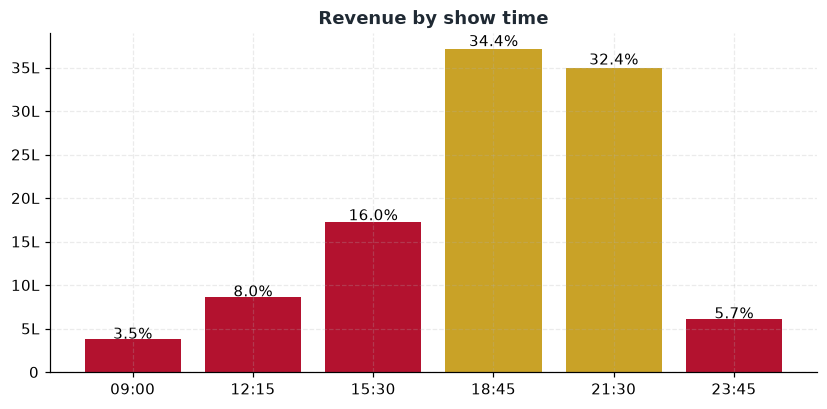

           revenue  bookings  share
show_time                          
09:00       379343       341    4.0
12:15       861524       956    8.0
15:30      1727621      1535   16.0
18:45      3708600      3080   34.0
21:30      3499681      2846   32.0
23:45       610798       553    6.0


In [5]:
slot = confirmed.groupby('show_time').agg(revenue=('total_amount','sum'),bookings=('booking_id','count')).sort_index()
slot['share']=slot['revenue']/slot['revenue'].sum()*100
colors=[GOLD if t in ['18:45','21:30'] else RED for t in slot.index]
fig,ax = plt.subplots(figsize=(9,4))
bars=ax.bar(slot.index, slot['revenue'], color=colors)
for b,s in zip(bars,slot['share']):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()*1.01,f'{s:.1f}%',ha='center')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
ax.set_title('Revenue by show time')
save(fig,'03_revenue_by_show_time.png')
plt.show()
print(slot.round(0))

## 3. Where does revenue come from?

### 3.1 City

saved 04_revenue_by_city.png


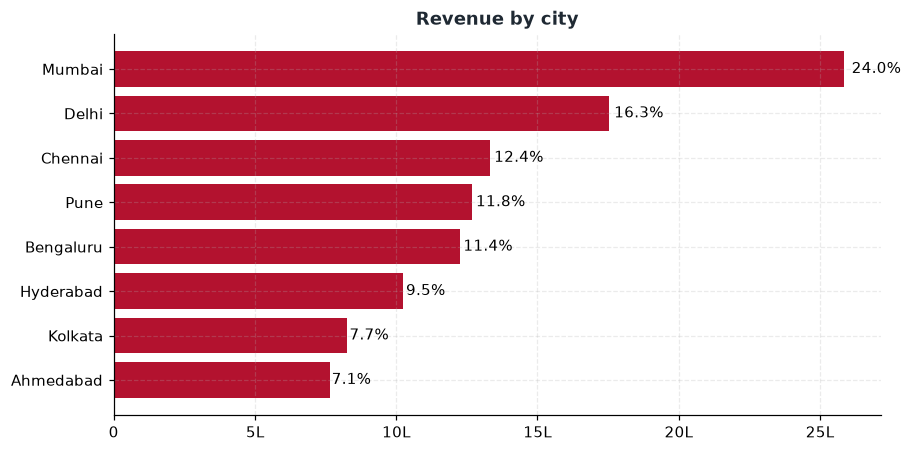

           revenue  bookings  customers  share     rpc
city                                                  
Mumbai     2587211      1770        663   24.0  3902.0
Delhi      1754679      1530        593   16.0  2959.0
Chennai    1333873      1142        373   12.0  3576.0
Pune       1270141      1075        342   12.0  3714.0
Bengaluru  1225897      1086        467   11.0  2625.0
Hyderabad  1024790      1045        394    9.0  2601.0
Kolkata     826646       880        299    8.0  2765.0
Ahmedabad   764330       783        277    7.0  2759.0


In [6]:
city = confirmed.groupby('city').agg(revenue=('total_amount','sum'),bookings=('booking_id','count'),customers=('customer_id','nunique')).sort_values('revenue')
city['share']=city['revenue']/city['revenue'].sum()*100
city['rpc']=city['revenue']/city['customers']
fig,ax = plt.subplots(figsize=(9,4.5))
ax.barh(city.index, city['revenue'], color=RED)
for i,(v,s) in enumerate(zip(city['revenue'],city['share'])):
    ax.text(v*1.01,i,f'{s:.1f}%',va='center')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(inr))
ax.set_title('Revenue by city')
save(fig,'04_revenue_by_city.png')
plt.show()
print(city.round(0).sort_values('revenue',ascending=False))

### 3.2 Movie concentration

saved 05_movie_pareto.png


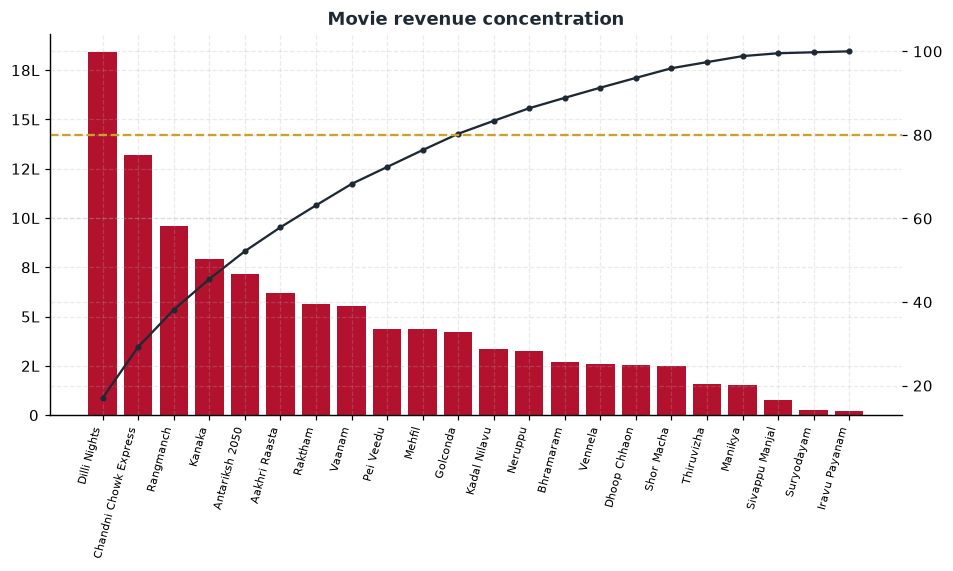

             movie_title          genre language  rating  revenue  share  \
0           Dilli Nights       Thriller    Hindi     8.1  1841194  17.07   
1  Chandni Chowk Express         Comedy    Hindi     6.9  1317244  12.21   
2              Rangmanch          Drama    Hindi     7.4   957638   8.88   
3                 Kanaka         Action    Tamil     7.2   793838   7.36   
4         Antariksh 2050         Sci-Fi    Hindi     7.5   717072   6.65   
5          Aakhri Raasta         Action    Hindi     7.8   618015   5.73   
6                Raktham         Action   Telugu     8.0   565851   5.25   
7                 Vaanam          Drama    Tamil     8.0   552561   5.12   
8              Pei Veedu  Horror-Comedy    Tamil     6.8   437916   4.06   
9                 Mehfil        Romance    Hindi     7.2   436668   4.05   

     cum  
0  17.07  
1  29.28  
2  38.16  
3  45.51  
4  52.16  
5  57.89  
6  63.14  
7  68.26  
8  72.32  
9  76.37  
Top5: 52.16


In [7]:
movie = confirmed.groupby('movie_title').agg(revenue=('total_amount','sum'),bookings=('booking_id','count'),tickets=('seats','sum'),rating=('rating','first'),genre=('genre','first'),language=('language','first')).sort_values('revenue',ascending=False).reset_index()
movie['share']=movie['revenue']/movie['revenue'].sum()*100
movie['cum']=movie['share'].cumsum()
fig,ax = plt.subplots(figsize=(10,4.5))
ax.bar(range(len(movie)), movie['revenue'], color=RED)
ax.set_xticks(range(len(movie)))
ax.set_xticklabels(movie['movie_title'], rotation=75, ha='right', fontsize=7)
ax2=ax.twinx()
ax2.plot(range(len(movie)), movie['cum'], color=CHARCOAL, marker='o', markersize=3)
ax2.axhline(80,ls='--',color=GOLD)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
ax.set_title('Movie revenue concentration')
save(fig,'05_movie_pareto.png')
plt.show()
print(movie[['movie_title','genre','language','rating','revenue','share','cum']].head(10).round(2))
print('Top5:', movie['share'].head(5).sum().round(2))

## 4. What are people buying?

### 4.1 Format

saved 06_format_revenue.png


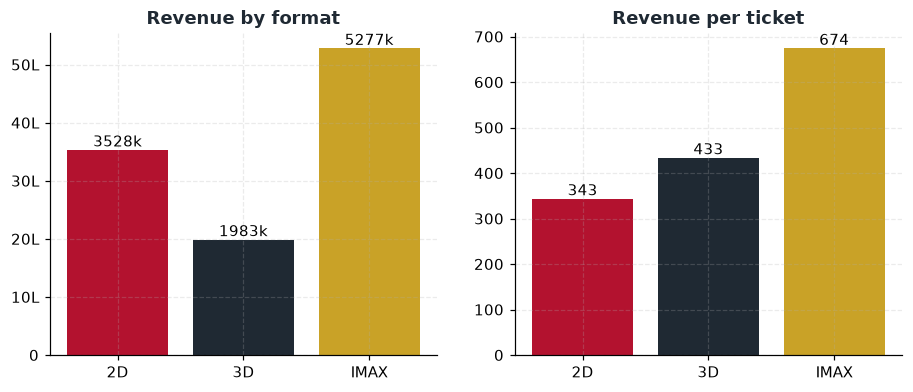

        revenue  tickets  share    rpt
format                                
2D      3527510    10281   33.0  343.0
3D      1983301     4578   18.0  433.0
IMAX    5276756     7831   49.0  674.0


In [8]:
fmt = confirmed.groupby('format').agg(revenue=('total_amount','sum'),tickets=('seats','sum')).reindex(['2D','3D','IMAX'])
fmt['share']=fmt['revenue']/fmt['revenue'].sum()*100
fmt['rpt']=fmt['revenue']/fmt['tickets']
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,3.8))
ax1.bar(fmt.index, fmt['revenue'], color=[RED,CHARCOAL,GOLD])
ax1.set_title('Revenue by format'); ax1.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
ax2.bar(fmt.index, fmt['rpt'], color=[RED,CHARCOAL,GOLD])
ax2.set_title('Revenue per ticket')
for ax in [ax1,ax2]:
    for p in ax.patches:
        ax.annotate(f'{p.get_height()/1e3:.0f}k' if p.get_height()>1e3 else f'{p.get_height():.0f}', (p.get_x()+p.get_width()/2,p.get_height()), ha='center', va='bottom')
save(fig,'06_format_revenue.png')
plt.show()
print(fmt.round(0))

### 4.2 Ticket type

saved 07_ticket_type_yield.png


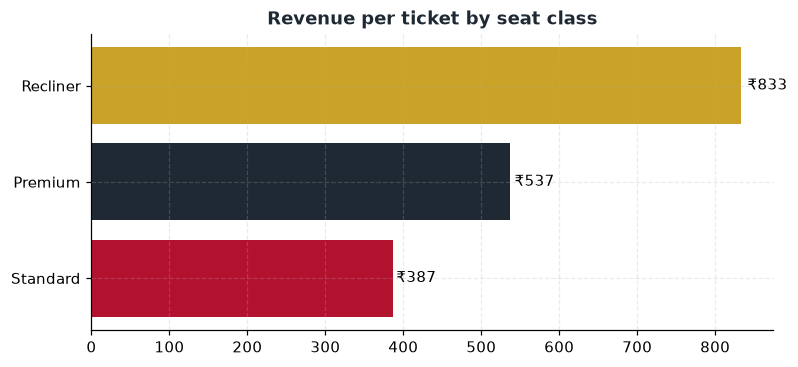

             revenue  tickets    rpt
ticket_type                         
Standard     5341474    13795  387.0
Premium      3569185     6642  537.0
Recliner     1876908     2253  833.0


In [9]:
tt = confirmed.groupby('ticket_type').agg(revenue=('total_amount','sum'),tickets=('seats','sum'))
tt['rpt']=tt['revenue']/tt['tickets']
tt=tt.sort_values('rpt')
fig,ax=plt.subplots(figsize=(8,3.5))
ax.barh(tt.index, tt['rpt'], color=[RED,CHARCOAL,GOLD])
for i,v in enumerate(tt['rpt']):
    ax.text(v*1.01,i,f'₹{v:,.0f}',va='center')
ax.set_title('Revenue per ticket by seat class')
save(fig,'07_ticket_type_yield.png')
plt.show()
print(tt.round(0))

### 4.3 Price grid

saved 08_price_grid.png


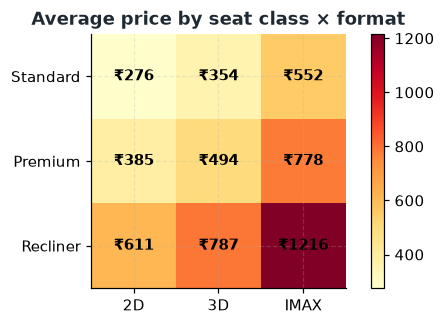

format          2D     3D    IMAX
ticket_type                      
Standard     276.0  354.0   552.0
Premium      385.0  494.0   778.0
Recliner     611.0  787.0  1216.0


In [10]:
grid = confirmed.pivot_table(index='ticket_type', columns='format', values='ticket_price', aggfunc='mean').round(0)
grid = grid.reindex(['Standard','Premium','Recliner'])[['2D','3D','IMAX']]
fig,ax=plt.subplots(figsize=(6,3))
im=ax.imshow(grid.values, cmap='YlOrRd')
ax.set_xticks(range(3)); ax.set_xticklabels(grid.columns)
ax.set_yticks(range(3)); ax.set_yticklabels(grid.index)
for i in range(3):
    for j in range(3):
        ax.text(j,i,f'₹{grid.values[i,j]:.0f}',ha='center',va='center',fontweight='bold')
ax.set_title('Average price by seat class × format')
plt.colorbar(im, ax=ax)
save(fig,'08_price_grid.png')
plt.show()
print(grid)

## 5. Who is buying?

### 5.1 Customer segments

saved 10_customer_segments.png


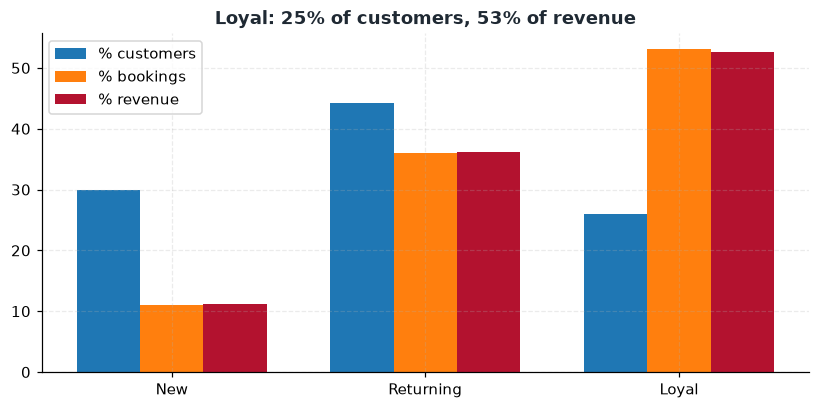

               customers  bookings  revenue  cust  book   rev
customer_type                                                
New                 1020      1020  1202536  29.9  11.0  11.1
Returning           1505      3351  3907880  44.2  36.0  36.2
Loyal                883      4940  5677151  25.9  53.1  52.6


In [11]:
seg = confirmed.groupby('customer_type').agg(customers=('customer_id','nunique'),bookings=('booking_id','count'),revenue=('total_amount','sum')).reindex(['New','Returning','Loyal'])
seg['cust']=seg['customers']/seg['customers'].sum()*100
seg['book']=seg['bookings']/seg['bookings'].sum()*100
seg['rev']=seg['revenue']/seg['revenue'].sum()*100
x=np.arange(3); w=0.25
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(x-w,seg['cust'],w,label='% customers')
ax.bar(x,seg['book'],w,label='% bookings')
ax.bar(x+w,seg['rev'],w,label='% revenue',color=RED)
ax.set_xticks(x); ax.set_xticklabels(seg.index)
ax.legend()
ax.set_title('Loyal: 25% of customers, 53% of revenue')
save(fig,'10_customer_segments.png')
plt.show()
print(seg.round(1))

### 5.2 Age groups

saved 11_age_group.png


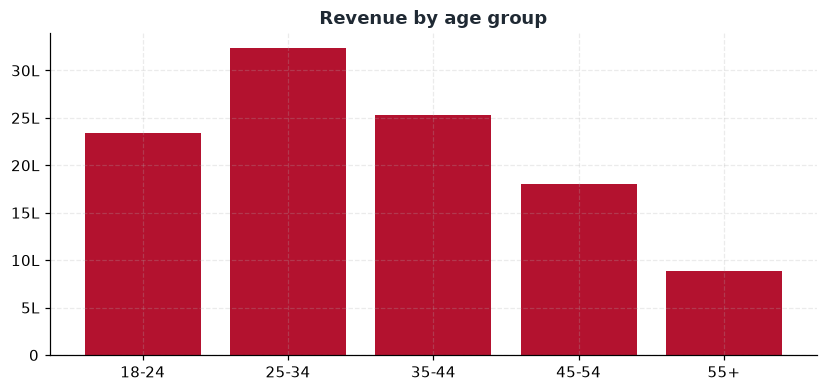

           bookings  revenue  share
age_group                          
18-24          2049  2337702   22.0
25-34          2801  3231339   30.0
35-44          2197  2532224   23.0
45-54          1505  1800397   17.0
55+             759   885905    8.0


In [12]:
age = confirmed.groupby('age_group').agg(bookings=('booking_id','count'),revenue=('total_amount','sum')).reindex(['18-24','25-34','35-44','45-54','55+'])
age['share']=age['revenue']/age['revenue'].sum()*100
fig,ax=plt.subplots(figsize=(9,3.8))
ax.bar(age.index, age['revenue'], color=RED)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(inr))
ax.set_title('Revenue by age group')
save(fig,'11_age_group.png')
plt.show()
print(age.round(0))

### 5.3 Payment methods

saved 12_payment_method.png


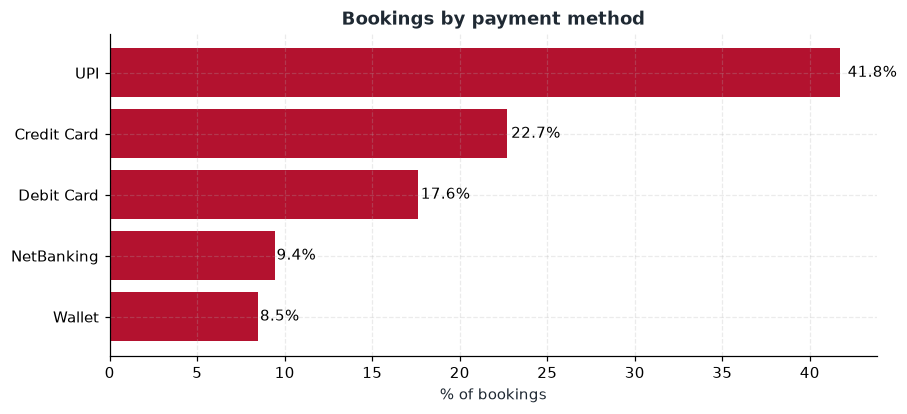

                bookings  share
payment_method                 
Wallet               850   8.50
NetBanking           944   9.44
Debit Card          1760  17.60
Credit Card         2271  22.71
UPI                 4175  41.75


In [13]:
pay = df.groupby('payment_method').agg(bookings=('booking_id','count')).sort_values('bookings')
pay['share']=pay['bookings']/pay['bookings'].sum()*100
fig,ax=plt.subplots(figsize=(9,3.8))
ax.barh(pay.index, pay['share'], color=RED)
for i,v in enumerate(pay['share']):
    ax.text(v*1.01,i,f'{v:.1f}%',va='center')
ax.set_title('Bookings by payment method')
ax.set_xlabel('% of bookings')
save(fig,'12_payment_method.png')
plt.show()
print(pay)

## 6. Occupancy & cancellations

### 6.1 Occupancy distribution

saved 13_occupancy_distribution.png


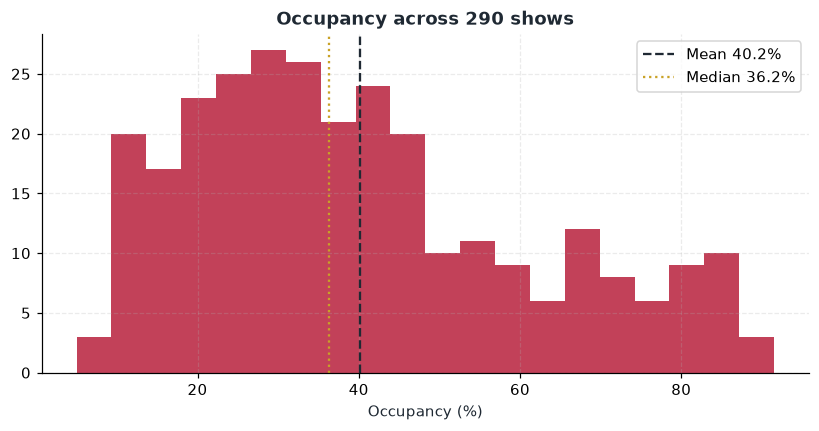

count    290.000
mean       0.402
std        0.210
min        0.050
25%        0.240
50%        0.362
75%        0.527
max        0.915
Name: occ, dtype: float64


In [14]:
shows = df.groupby('show_id').agg(occ=('show_occupancy_rate','first'),cap=('seats_capacity','first'),time=('show_time','first'),fmt=('format','first'))
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(shows['occ']*100,bins=20,color=RED,alpha=0.8)
ax.axvline(shows['occ'].mean()*100,ls='--',color=CHARCOAL,label=f'Mean {shows["occ"].mean()*100:.1f}%')
ax.axvline(shows['occ'].median()*100,ls=':',color=GOLD,label=f'Median {shows["occ"].median()*100:.1f}%')
ax.legend()
ax.set_title('Occupancy across 290 shows')
ax.set_xlabel('Occupancy (%)')
save(fig,'13_occupancy_distribution.png')
plt.show()
print(shows['occ'].describe().round(3))

### 6.2 Occupancy by show time

saved 14_occupancy_by_time.png


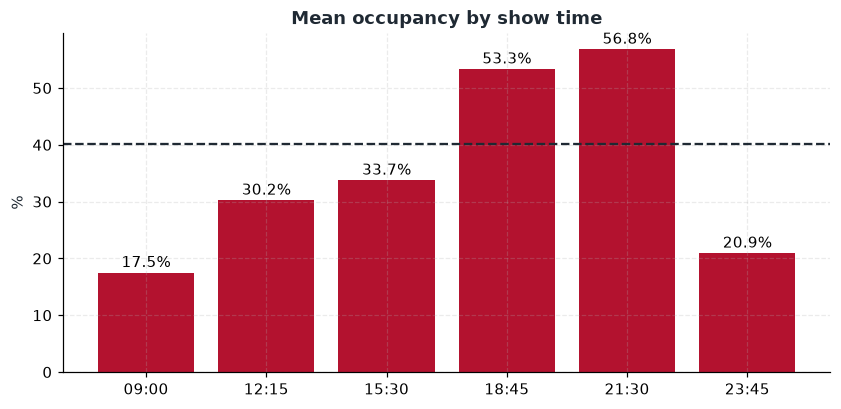

       shows       occ
time                  
09:00     25  0.174858
12:15     45  0.302299
15:30     57  0.337467
18:45     72  0.533177
21:30     61  0.568015
23:45     30  0.209146


In [15]:
so = shows.groupby('time').agg(shows=('occ','count'),occ=('occ','mean')).sort_index()
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(so.index, so['occ']*100, color=RED)
ax.axhline(shows['occ'].mean()*100,ls='--',color=CHARCOAL)
for i,v in enumerate(so['occ']*100):
    ax.text(i,v+1,f'{v:.1f}%',ha='center')
ax.set_title('Mean occupancy by show time')
ax.set_ylabel('%')
save(fig,'14_occupancy_by_time.png')
plt.show()
print(so)

### 6.3 Cancellations by channel

saved 15_cancellation_by_channel.png


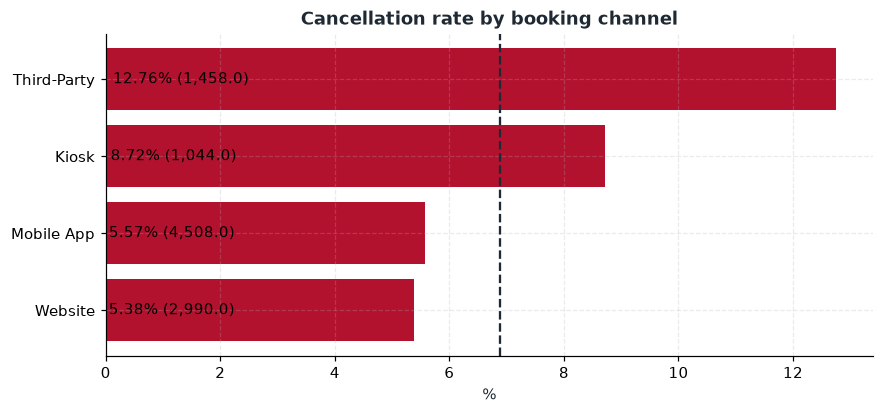

                 bookings  cancel        pct
booking_channel                             
Website              2990     161   5.384615
Mobile App           4508     251   5.567879
Kiosk                1044      91   8.716475
Third-Party          1458     186  12.757202


In [16]:
ch = df.groupby('booking_channel').agg(bookings=('booking_id','count'),cancel=('booking_status',lambda x:(x=='Cancelled').sum()))
ch['pct']=ch['cancel']/ch['bookings']*100
ch=ch.sort_values('pct')
fig,ax=plt.subplots(figsize=(9,3.8))
ax.barh(ch.index, ch['pct'], color=RED)
for i,v in enumerate(ch['pct']):
    ax.text(v*0.01,i,f'{v:.2f}% ({ch.iloc[i]["bookings"]:,})',va='center')
ax.axvline((df['booking_status']=='Cancelled').mean()*100,ls='--',color=CHARCOAL)
ax.set_title('Cancellation rate by booking channel')
ax.set_xlabel('%')
save(fig,'15_cancellation_by_channel.png')
plt.show()
print(ch)

## 7. Lead time

saved 16_lead_time.png


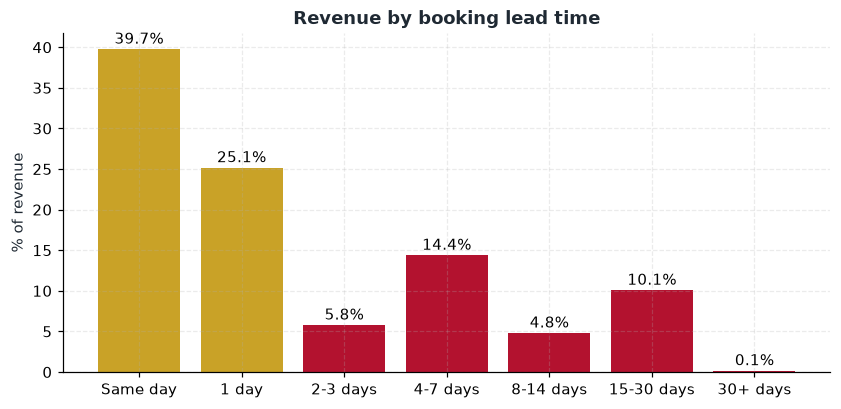

            bookings  revenue      share
lb                                      
Same day        3735  4286958  39.739804
1 day           2359  2712724  25.146764
2-3 days         547   621599   5.762180
4-7 days        1278  1549550  14.364221
8-14 days        457   516140   4.784582
15-30 days       922  1084906  10.057004
30+ days          13    15690   0.145445
Median lead: 1.0 | Within 24h: 64.9 %


In [17]:
LEAD_BINS = [-1,0,1,3,7,14,30,10000]
LEAD_LABELS = ['Same day','1 day','2-3 days','4-7 days','8-14 days','15-30 days','30+ days']
confirmed['lb']=pd.cut(confirmed['lead_days'], LEAD_BINS, labels=LEAD_LABELS)
lead = confirmed.groupby('lb',observed=False).agg(bookings=('booking_id','count'),revenue=('total_amount','sum'))
lead['share']=lead['revenue']/lead['revenue'].sum()*100
colors=[GOLD if x in ['Same day','1 day'] else RED for x in lead.index]
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(lead.index.astype(str), lead['share'], color=colors)
for i,v in enumerate(lead['share']):
    ax.text(i,v+0.7,f'{v:.1f}%',ha='center')
ax.set_title('Revenue by booking lead time')
ax.set_ylabel('% of revenue')
save(fig,'16_lead_time.png')
plt.show()
print(lead)
print('Median lead:', confirmed['lead_days'].median(), '| Within 24h:', lead.loc[['Same day','1 day'],'share'].sum().round(1),'%')

## 8. Rating vs demand

saved 17_rating_vs_bookings.png


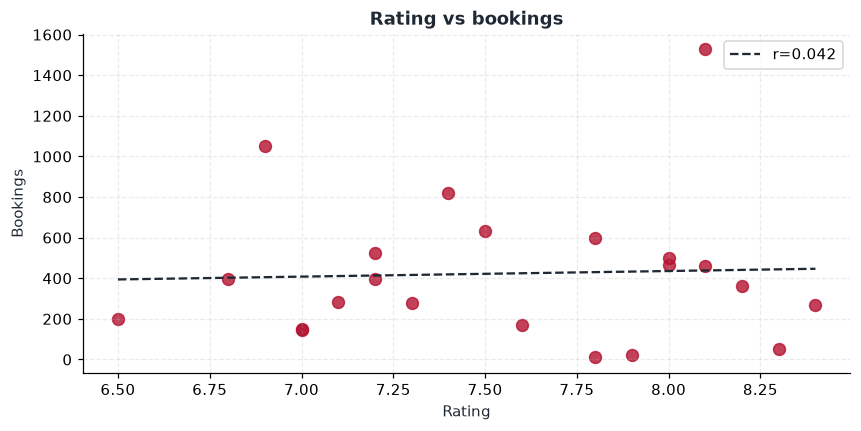

                       rating  bookings  shows  revenue        bps
movie_title                                                       
Dhoop Chhaon              8.4       267     11   252371  24.272727
Sivappu Manjal            8.3        52      1    74558  52.000000
Neruppu                   8.2       363     12   326036  30.250000
Golconda                  8.1       460     15   421973  30.666667
Dilli Nights              8.1      1528     41  1841194  37.268293
Raktham                   8.0       463     10   565851  46.300000
Vaanam                    8.0       499     14   552561  35.642857
Iravu Payanam             7.9        24      2    23666  12.000000
Suryodayam                7.8        11      1    25250  11.000000
Aakhri Raasta             7.8       600     20   618015  30.000000
Bhramaram                 7.6       172      5   268566  34.400000
Antariksh 2050            7.5       631     16   717072  39.437500
Rangmanch                 7.4       818     30   957638  27.26

In [18]:
mv = confirmed.groupby('movie_title').agg(rating=('rating','first'),bookings=('booking_id','count'),shows=('show_id','nunique'),revenue=('total_amount','sum'))
mv['bps']=mv['bookings']/mv['shows']
r = mv['rating'].corr(mv['bookings'])
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(mv['rating'], mv['bookings'], s=60, color=RED, alpha=0.8)
m,b = np.polyfit(mv['rating'], mv['bookings'], 1)
x=np.linspace(mv['rating'].min(),mv['rating'].max(),50)
ax.plot(x,m*x+b,'--',color=CHARCOAL,label=f'r={r:.3f}')
ax.legend()
ax.set_title('Rating vs bookings')
ax.set_xlabel('Rating')
ax.set_ylabel('Bookings')
save(fig,'17_rating_vs_bookings.png')
plt.show()
print(mv.sort_values('rating',ascending=False))
print('r=',r)

## 9. Summary

All numbers reconcile with SQL. IMAX dominates revenue (price-driven), evening slots are constrained, loyal customers carry half of revenue, cancellations cluster on Third-Party, demand is last-minute, and rating shows no relationship with bookings (r~0). The chart narratives separate price effects from volume effects where it matters.